# 2.FuncionOnda
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [1]:
from sympy import *       # Importa todas las funciones de sympy
init_printing()           # Edita las fórmulas
x,L,k=symbols('x,L,k')    # Símbolos con los cuales se trabajará algebraicamente

import matplotlib.pyplot as plt  # Paquete gráfico
import numpy as np

# Está función cuyos argumentos son una función real de una variable x, definida sobre el intervalo (a,b), permite determinar si tenemos una función cuadrado integrable. Si CI(f(x),a,b) arroja un valor numérico la función es cuadrado integrable, de lo contrario no lo es.

def CI(f,a,b):
    return integrate(f**2,(x,a,b))

# Esta función toma la función de densidad de probabilidad g(x) y encuentra P(a<X<b).

def Prob(g,a,b):
    return N(integrate(g,(x,a,b)))

# Dada una función de onda f(x) definida en el intervalo [a,b], la función Nor(f(x),a,b) nos permitirá encontrar la constante de normalización y la función normalizada.

def Nor(f,a,b):
    A=1/sqrt(integrate(f**2,(x,a,b)))
    return (A,A*f)

# **FUNCIÓN DE ONDA ASOCIADA A UNA PARTÍCULA**

## **Preliminares**

Recordemos que los números complejos tienen la forma $a+bi$, donde $a$ y $b$ son números reales y $i$ es un símbolo que satisface $i^2=-1$ (estos números satisfacen las propiedades aritméticas usuales de los números reales). Para el complejo $z=a+bi$ decimos que $a$ es la parte real de $z$ y $b$ es la parte imaginaria de $z$, las cuales se denotan por $a=Re(z)$ y $b=Im(z)$, respectivamente. También decimos que $z^*=a-bi$ es el $conjugado \ de \ z$. Adicionalmente se define la norma o módulo $|z|$ de $z$ por: $|z|=\sqrt{a^2+b^2}$, la cual es un número real (note que $|z|^2=zz^*$).

Por ejemplo: sean $z=5+\sqrt{3}i$ y $w=-5i$.

En este caso: $Re(z)=5$, $Im(z)=\sqrt{3}$, $|z|=\sqrt{5^2+(\sqrt{3})^2}=\sqrt{28}$. Por lo tanto, $zz^*=28$.    
$\hspace{1.6cm}$ $Re(w)=0$, $Im(z)=-5$, $|z|=\sqrt{0^2+(-5)^2}=5$. Por lo tanto, $zz^*=25$.

$\textbf{Nota:}$ Una función compleja tiene la forma $h=f+gi$, donde $f$ y $g$ son funciones de valor real. Por los tanto, su norma $|h|=\sqrt{f^2+g^2}$ es una función de valor real que satisface: $|h|^2=hh^*$.



## **FUNCIÓN DE ONDA**

La función de onda $\psi(x,t)$ asociada a una partícula contiene toda la información sobre el comportamiento de la partícula, en particular el cuadrado de su norma $|\psi(x,t)|^2=\psi\psi^*$ es una función de densidad de probabilidad. La función de onda es una función de valor real (o valor complejo) que depende de la coordenada $x$ y el tiempo $t$ para movimientos unidimensionales, y depende de un vector $n$-coordenado $(x_1,x_2,...,x_n)$ y el tiempo $t$ en el caso multidimensional. La función de onda debe tener buenas propiedades, es decir, debe ser continua, diferenciable y cuadrado-integrable. Por cuadrado-integrable se entide que la integral sobre todo el espacio del cuadrado de la norma de la función es un valor finito, es decir

$$\int_{-\infty}^{+\infty}{|\psi(x,t)|^2dx}=\int_{-\infty}^{+\infty}\psi\psi^*<+\infty$$

$\textbf{Nota}$: Teniendo en cuenta que en este curso se empleará la ecuación de Schrödinger independiente del tiempo, se trabajará solamente funciones de onda $\psi(x)$ independientes del tiempo. Por ejemplo, Consideremos las funciones $\psi(x)=x^3$ y $\phi(x)=e^{-x^2}$ (donde $0\leq x <\infty$), para las cuales se gráfican a continuación los cuadrados de sus normas.

$$|\psi(x)|^2=x^3x^3=x^6 \ \ y \ \ |\phi(x)|^2=e^{-x^2}e^{-x^2}=e^{-2x^2} $$

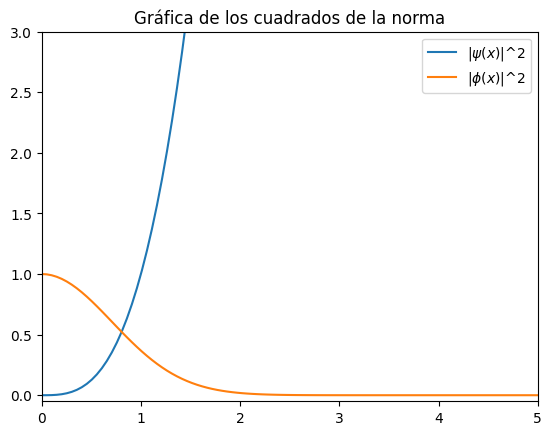

In [2]:
#@title
x1=np.linspace(0,5,100)
y1=x1**3
y2=np.exp(-x1**2)

fig, ax= plt.subplots()
ax.plot(x1,y1,label='|$\psi(x)$|^2')
ax.plot(x1,y2,label='|$\phi(x)$|^2')
ax.set_ylim(-0.05,3)
ax.set_xlim(0,5)
ax.set_title('Gráfica de los cuadrados de la norma')
ax.legend()

Tanto $\psi(x)=x^3$ como $\phi(x)=e^{-x^2}$ son continuas y diferenciables. Como $\int_{-\infty}^{+\infty}{|\psi(x)|^2dx}$ y $\int_{-\infty}^{+\infty}{|\phi(x)|^2dx}$ representan el área bajo las curvas de $|\psi(x)|^2$ y $|\phi(x)|^2$, entre cero e infinito, probablemente $\psi(x)$ será cuadrado integrable, mientras que $\phi(x)$ no lo será (tal cual podemos apreciarlo en la gráfica anterior). Si calculamos las integrales respectivas se obtienen los siguientes resultados:

In [3]:
#@title
from IPython.display import display, Math, Latex

f=x**3
g=exp(-x**2)
display(Math('Valores \ de \ las \ integrales \ de \ |\psi(x)|^2 \ y \ |\phi(x)|^2 \ desde \  cero \ hasta \ infinito'))
integrate(f**2,(x,0,oo)), integrate(g**2,(x,0,oo))

<IPython.core.display.Math object>

⎛   √2⋅√π⎞
⎜∞, ─────⎟
⎝     4  ⎠

Como vemos $\psi(x)$ no es cuadrado-integrable, puesto que $\int_{0}^{+\infty}{|\psi(x)|^2dx}=\infty$, mientras que $\phi(x)$ si lo es, puesto que $\int_{0}^{+\infty}{|\phi(x)|^2dx}=\frac{\sqrt{2}\sqrt{\pi}}{4}$. En este caso $\psi(x)$ no puede ser una función de onda, mientras que $\phi(x)$ si lo es. La función $CI(\psi,a,b)$, cuyos argumentos son una función real de una variable $x$, $\psi(x)$, definida sobre el intervalo $(a,b)$, permite determinar si $\psi$ es una función cuadrado integrable. Si $CI(\psi,a,b)$ arroja un valor finito la función es cuadrado integrable, de lo contrario no lo es.

Por ejemplo consideremos la función $\psi(x)=\frac{x^3}{x+1}$ desde $-\infty$ hasta $30$:

In [ ]:
CI(x**3/(x+1),-oo,30)   # Note que el extremo infinito se genera con doble o (minúscula), es decir, oo
                        # La potencia n-ésima de x se dígita como x**n, el producto de a con b, como a*b, y el cociente de a con b por a/b

Como el valor de la integral es infinito, la función no puede ser cuadrado integrable.

### **Ejercicio 1**

Determine si las siguientes funciones pueden ser funciones de onda:

1. $f(x)=\sqrt{\frac{54}{\pi}}\frac{1}{x^2+9}$ en el intervalo $(-\infty,\infty)$.
2. $g(x)=\frac{1+x^2}{1+x}$ en el intervalo $(-\infty,\infty)$.
3. $h(x)=\frac{x^2}{3}$ en el intervalo $[-1,2]$.
4. $l(x)=5(1-x)^{-4}$ para $[0,1]$.
5. $j(x)=3x^{-4}$ para $(1,\infty)$.
6. $w(x)=\frac{sin(x)}{x}$ para $(0,\infty)$.

Nota: El número $\pi$ se digita como pi, la raíz $\sqrt[n]{x^m}$ se puede escribir como x**(m/n) y la función $sin(x)$ se digita igual.

## **INTERPRETACIÓN PROBABILÍSTICA DE LA FUNCIÓN DE ONDA**

La interpretación de la función de onda en términos de la posición de una partícula fue sugerida por $\textbf{Max Born}$, el cual tomo como punto de partida la teoría ondulatoría de las ondas electromagnéticas. Para una onda electromagnética el cuadrado de su amplitud corresponde a su intensidad (es decir, a la cantidad de energía transmitida por la onda por unidad de área y por unidad de tiempo), la cual puede ser interpretada en términos cuánticos como una medida de la probabilidad de encontrar un fotón en cierta región del espacio. Entonces la interpretación de Born de la función de onda $\psi$ se centra en el cuadrado de su norma (o módulo) $|\psi(x)|^2$, el cual postula que el valor $|\psi(x)|^2$ es proporcional a la probabilidad de encontrar la partícula alrededor del punto $x$, es decir, la probabilidad de encontrar a la partícula en la región comprendida entre $x$ y $x+dx$ es proporcional a $|\psi(x)|^2dx$. Así, para una función de onda $\psi(x)$ el cuadrado de su norma $|\psi(x)|^2$ corresponde a una función de densidad de probabilidad, y por lo tanto la integral $\int_{a}^{b}|\psi(x)|^2dx$ representa la probabilidad de encontrar la partícula en la región $a\leq x \leq b$.

La interpretación de Born dista de los valores negativos o complejos que pueda asumir la función de onda $\psi(x)=\phi(x)+\theta(x)i$, puesto que $|\psi(x)|^2=\phi(x)^2+\theta(x)^2$ es un número real positivo. Sin embargo, la presencia de valores negativos y positivos en una función de onda tendrá significado cuando se sumen paquetes de ondas, ya que en este caso cabe la posibilidad de que se presente interferencia tanto constructiva como destructiva.



En general si $X$ es la variable aleatoria asociada a la posición de una partícula, una $\textbf{función de densidad de probabilidad}$ para $X$, es una función $f(x)$ que satisface:

a.  $f(x)\geq 0$ para todo $x \hspace{2.5cm} $                       (Condición de positividad)

b.  $\int_{-\infty}^{+\infty}{f(x)}dx=1  \hspace{3.15cm}$                (La probabilidad de encontrar la partícula en todo el espacio es igual a 1 )

c. $P(a\leq X \leq b)=\int_{a}^{b}{f(x)dx}  \hspace{1.73cm}$           (Probabilidad de encontrar la partícula en el intervalo que va desde $a$ hasta $b$)

De acuerdo con la interpretación de Max Born, si $\psi(x)$ es la función de onda asociada a una partícula, el cuadrado de su norma $|\psi(x)|^2$ es una función de densidad de probabilidad. Por lo tanto $|\psi(x)|^2$ es positiva o cero, satisface la condición de normalización
($\int_{-\infty}^{+\infty}{|\psi(x)|^2}dx=1$) y la probabilidad de encontrar la partícula en el intervalo que va desde $a$ hasta $b$ es igual a
$\int_{a}^{b}{|\psi(x)|^2}dx$.

Por ejemplo, si $\phi(x)=\frac{1}{4}xe^{-x/2}$ para $x\geq 0$ y es igual a $0$ para $x<0$, entonces $\phi(x)$ es una función de densidad de probabilidad que tiene el siguiente aspecto:

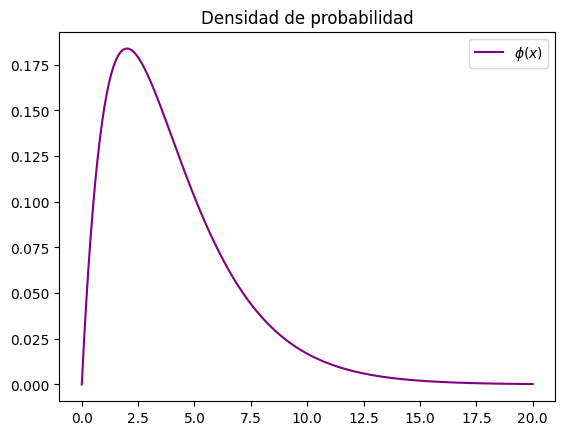

In [4]:
#@title
x1=np.linspace(0,20,200)
y1=(1/4)*x1*np.exp(-x1/2)


fig, ax= plt.subplots()
ax.plot(x1,y1,label='$\phi(x)$',color='purple')
ax.set_title('Densidad de probabilidad')
ax.legend()

En las siguientes gráficas podemos ver los valores numéricos de las probabilidades: $P(2\leq X \leq 4)$ y $P(X \geq 6)$.

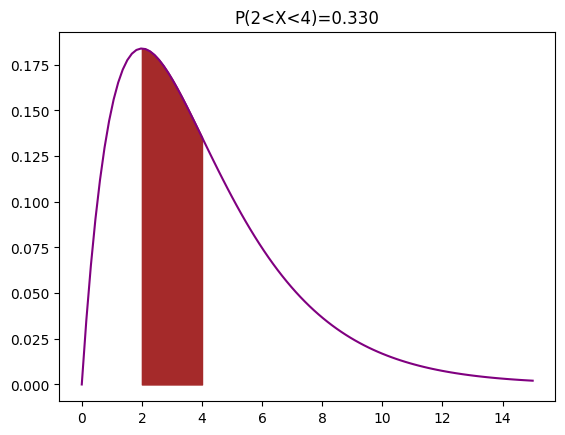

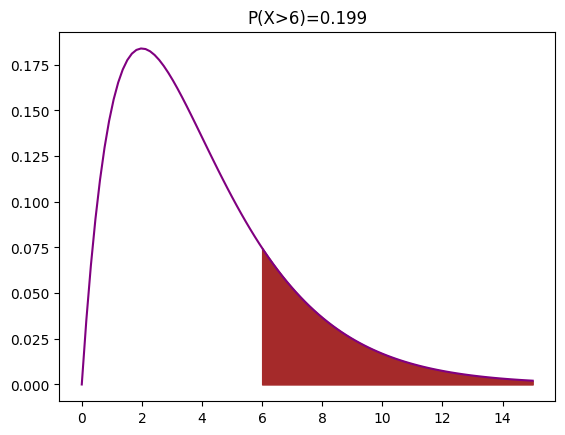

In [7]:
#@title
from sympy import *       # Importa todas las funciones de sympy
init_printing()           # Edita las fórmulas
x=symbols('x')            # Símbolos con los cuales se trabajará algebraicamente

import numpy as np
from matplotlib import pyplot as plt

x1 = np.linspace(0,15,100)
y1 = 0.25*x1*np.exp(-x1/2)
x2 = np.linspace(2,4,50)
y2 = 0.25*x2*np.exp(-x2/2)
x3 = np.linspace(6,15,50)
y3 = 0.25*x3*np.exp(-x3/2)

prob1=N(integrate(0.25*x*exp(-x/2),(x,2,4)))               # Probabilida de que el valor de X este entre 2 y 4.
prob2=N(integrate(0.25*x*exp(-x/2),(x,6,oo)))              # Probabilida de que el valor de X sea mayor o igual a 6.

fig, a1=plt.subplots()
a1.plot(x1,y1,color='purple')
a1.set_title('P(2<X<4)={:2.3f}'.format(prob1))
a1.fill_between(x2, y2, color='brown')

fig, a1=plt.subplots()
a1.plot(x1,y1,color='purple')
a1.set_title('P(X>6)={:2.3f}'.format(prob2))
a1.fill_between(x3, y3,color='brown')

Si una función $\psi(x)$ es una solución de la ecuación de Schrödinger, la integral $\int_{-\infty}^{+\infty}{|\psi(x)|^2dx}$ no tiene porque ser igual a $1$, es decir, no está obligada a satisfacer la condición de normalización, con lo cual colapsaría la interpretación probabilística de la función de onda. Sin embargo este requerimiento no es para alarmarse, puesto que si $\psi(x)$ es solución a la ecuación de Schrödinger también lo es $A\psi(x)$, donde $A$ es una constante. Por lo tanto lo que debemos hacer es econtrar $A$ de tal forma que $\int_{-\infty}^{+\infty}{|A\psi(x)|^2dx}=1$. Este proceso se conoce como **normalización de la función de onda**.

Dada una función de onda $\psi(x)$ definida en el intervalo $[a,b]$, la función $Nor(\psi(x),a,b)$ nos permitirá encontrar la constante de normalización y la función normalizada. Por ejemplo, encontremos la constante de normalización para $\psi(x)=e^{-x^2}$, si se define sobre el intervalo $[0,\infty)$.

In [8]:
Nor(exp(-x**2),0,oo)  # La función exponencial se digita como exp(x)

TypeError: ignored

Normalización de $sin(\frac{\pi x}{L})$ para $0\leq x\leq L$.

In [9]:
Nor(sin((pi*x)/L),0,L)

TypeError: ignored

### **Ejercicio 2**

Considere las funciones propuestas en el ejercicio 1. Tome solamente aquellas que pueden ser funciones de onda y normalicelas.

### **Ejercicio 3**

Normalice las siguientes funciones de onda:

1. $\psi(x)=\frac{10}{(x+10)^2}$ para $0\leq x \leq \infty$.

2. $\phi(x)=(kx-x^2)$ para $0\leq x \leq k$.

3. $\theta(x)=e^{-kx^2}$ para $0\leq x \leq k $.

Nota: La función exponencial $e^{-kx^2}$  se dígita $exp(-k*x**2)$.

### **Ejercicio 4**

En un instante de tiempo dado una partícula unidimensional está descrita por $\psi(x)=(\frac{2}{b^3})^{1/2}xe^{-|x|/b}$, donde $b=3nm$. Si se hace una medida de la posición $x$ de la partícula en dicho instante, halle la probabilidad de que:

1. La partícula se encuentre entre $0.9$ y $0.9001nm$.

2. Entre $0$ y $2nm$.

3. Para que valor de $x$ es máxima la densidad de probabilidad.

4. Compruebe que $\psi(x)$ está normalizada.

**Ayuda:** Si $\psi(x)$ es una función de densidad de probabilidad, la función $Prob(\psi(x),a,b)$ permite encontrar la probabilidad de que la variable $x$ tome valores entre $a$ y $b$.

# **BIBLIOGRAFÍA**

Atkins, P. Physical Chemistry, Ed 8, WH Freeman, 2006.

Levine, I. Química Cuántica, Ed 5, 2001.

McQuarrie D., Quantum Chemistry, Viva Books, 2016.

Sears, Zemansky, Física Universitaria, vol 2, Addison-Wesley, 2009.